In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import Logistic

In [141]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

In [142]:
df.head(10).T

,0,1,2,3,4,5,6,7,8,9
id,9046,51676,31112,60182,1665,56669,53882,10434,27419,60491
gender,Male,Female,Male,Female,Female,Male,Male,Female,Female,Female
age,67.0,61.0,80.0,49.0,79.0,81.0,74.0,69.0,59.0,78.0
hypertension,0,0,0,0,1,0,1,0,0,0
heart_disease,1,0,1,0,0,0,1,0,0,0
ever_married,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes
work_type,Private,Self-employed,Private,Private,Self-employed,Private,Private,Private,Private,Private
Residence_type,Urban,Rural,Rural,Urban,Rural,Urban,Rural,Urban,Rural,Urban
avg_glucose_level,228.69,202.21,105.92,171.23,174.12,186.21,70.09,94.39,76.15,58.57
bmi,36.6,NaN,32.5,34.4,24.0,29.0,27.4,22.8,NaN,24.2


In [143]:
df = df.drop(columns="id")

In [144]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   str    
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 594.7 KB


In [145]:
df.shape

(5110, 11)

In [146]:
df.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


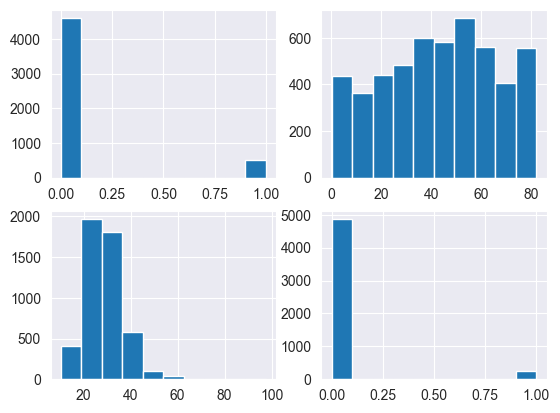

In [147]:
plt.subplot(2,2,1)
plt.hist(x="hypertension",data=df)
plt.subplot(2,2,2)
plt.hist(x="age",data=df)
plt.subplot(2,2,3)
plt.hist(x="bmi",data=df)
plt.subplot(2,2,4)
plt.hist(x="stroke",data=df)
plt.show()

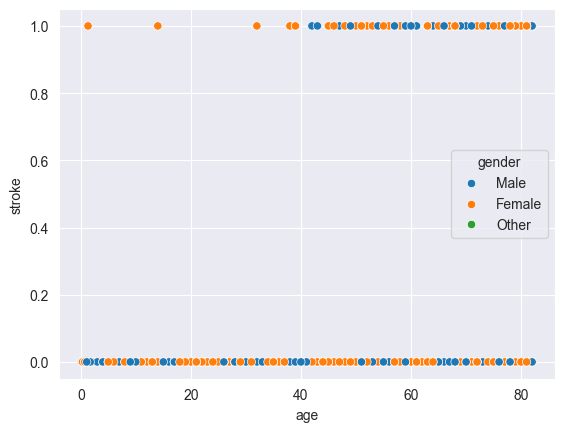

In [148]:
sns.scatterplot(x="age",y="stroke",data=df,hue="gender")
plt.show()

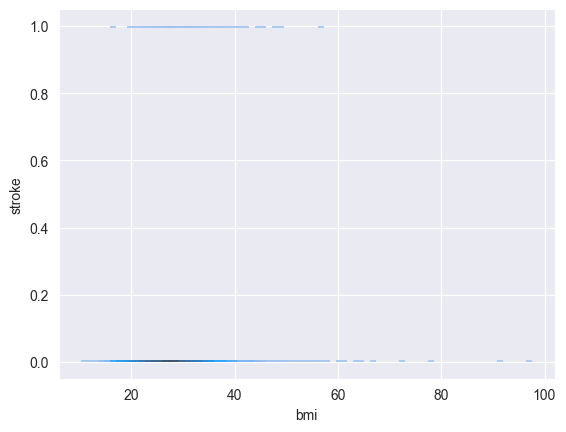

In [149]:
sns.histplot(x="bmi",y="stroke",data=df)
plt.show()

In [150]:
CategoricC = df.select_dtypes(include=["str","object"]).columns

In [151]:
CategoricC

Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='str')

In [152]:
NumericC = df.select_dtypes(include=["float64","int64"]).columns

In [153]:
NumericC

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'stroke'],
      dtype='str')

In [154]:
numCorr = df[NumericC].corr()

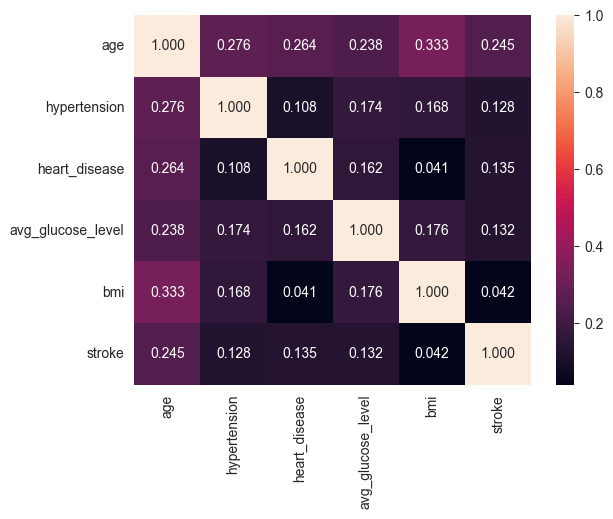

In [155]:
sns.heatmap(numCorr, annot=True, fmt=".3f")
plt.show()

In [156]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [157]:
df["stroke"].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [158]:
df[df["stroke"] == 1].groupby("bmi").size().sum()

np.int64(209)

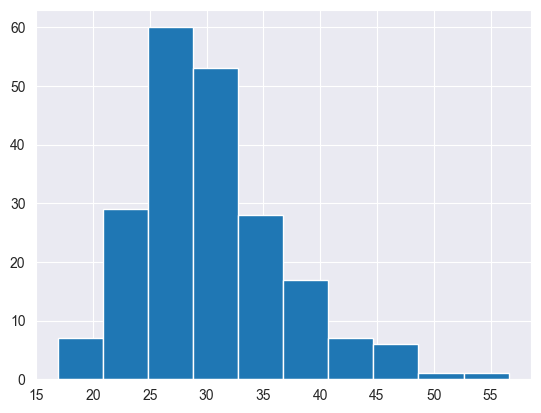

In [159]:
plt.hist(data=df[df["stroke"] == 1], x="bmi")
plt.show()

In [160]:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

In [161]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [162]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [163]:
df["smoking_status"].value_counts()

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

In [164]:
z = ["gender","ever_married","work_type","Residence_type","smoking_status"]

In [165]:
for col in z:

    print(col)
    print("***********************")
    x = df[col].value_counts()
    print(x)
    print("\n---------------------\n")

gender
***********************
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

---------------------

ever_married
***********************
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

---------------------

work_type
***********************
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

---------------------

Residence_type
***********************
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

---------------------

smoking_status
***********************
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

---------------------



In [166]:
df["work_type"] = df["work_type"].replace({"children": "Not_working", "Never_worked": "Not_working"})

In [167]:
df = df[df["gender"] != "Other"].reset_index(drop=True)

In [168]:
df = pd.get_dummies(df, drop_first=True, dtype=int)

In [169]:
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Not_working,work_type_Private,work_type_Self-employed,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,1,1,0,1,0,1,1,0,0
1,61.0,0,0,202.21,28.1,1,0,1,0,0,1,0,0,1,0
2,80.0,0,1,105.92,32.5,1,1,1,0,1,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,0,1,0,1,0,1,0,0,1
4,79.0,1,0,174.12,24.0,1,0,1,0,0,1,0,0,1,0


In [170]:
from sklearn.model_selection import train_test_split

In [171]:
X = df.drop("stroke",axis=1)
y = df["stroke"]

In [172]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.28, random_state=28, stratify=y)

In [173]:
from sklearn.preprocessing import StandardScaler

In [174]:
Scaler = StandardScaler()

In [175]:
X_train = Scaler.fit_transform(X_train)
X_test = Scaler.transform(X_test)

In [176]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
logReg = LogisticRegression(max_iter=1000,class_weight="balanced")

In [177]:
logReg.fit(X_train, y_train)
y_pred = logReg.predict(X_test)

In [178]:
print("Classification Report\n\n", classification_report(y_test, y_pred))

Classification Report

               precision    recall  f1-score   support

           0       0.99      0.75      0.85      1361
           1       0.14      0.80      0.24        70

    accuracy                           0.75      1431
   macro avg       0.56      0.78      0.55      1431
weighted avg       0.95      0.75      0.82      1431



In [179]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [180]:
models = {
    "KNN": KNeighborsClassifier(),
    "SVC": SVC(class_weight="balanced"),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=28),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=28),
}

In [181]:
results = []
for name,model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
        }
    )

pd.DataFrame(results).sort_values("F1", ascending=False)

C:\Users\Vmuha\PycharmProjects\PythonProject2\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,Accuracy,Precision,Recall,F1
1,SVC,0.784067,0.132308,0.614286,0.217722
2,Naive Bayes,0.825297,0.134146,0.471429,0.208861
3,Decision Tree,0.923131,0.115385,0.085714,0.098361
0,KNN,0.948288,0.250000,0.028571,0.051282
4,Random Forest,0.951083,0.000000,0.000000,0.000000


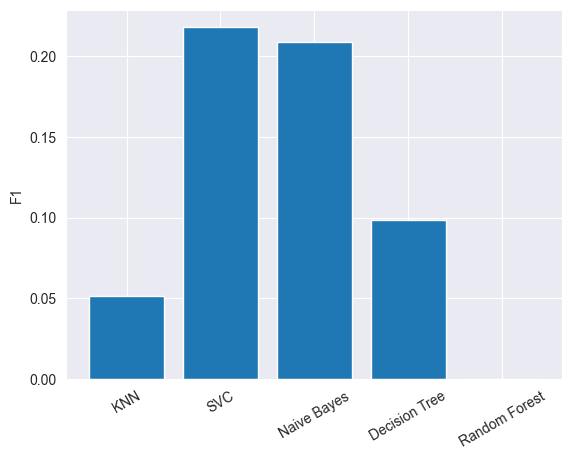

In [182]:
Res = pd.DataFrame(results)
plt.bar(Res["Model"], Res["F1"])
plt.ylabel("F1")
plt.xticks(rotation=30)
plt.show()

In [183]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [184]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()


In [185]:
boost_models = {
    "XGBoost": XGBClassifier(scale_pos_weight=ratio, random_state=28),
    "LightGBM": LGBMClassifier(scale_pos_weight=ratio, random_state=28, verbose=-1),
}

In [186]:
boost_results = []

for name, m in boost_models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)


    boost_results.append(
        {

        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),

        }
    )

pd.DataFrame(boost_results).sort_values("F1", ascending=False)

,Model,Accuracy,Precision,Recall,F1
1,LightGBM,0.911251,0.164706,0.200000,0.180645
0,XGBoost,0.927324,0.113636,0.071429,0.087719


In [187]:
boost_models = {
    "XGBoost": XGBClassifier(scale_pos_weight=ratio, max_depth=3, n_estimators=100,
                             learning_rate=0.05, random_state=28),
    "LightGBM": LGBMClassifier(scale_pos_weight=ratio, max_depth=3, num_leaves=7,
                               n_estimators=100, learning_rate=0.05,
                               random_state=28, verbose=-1),
}

boost_results = []
for name, m in boost_models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)


    boost_results.append(
        {

        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),

        }
    )

pd.DataFrame(boost_results).sort_values("F1", ascending=False)

,Model,Accuracy,Precision,Recall,F1
1,LightGBM,0.772187,0.146409,0.757143,0.245370
0,XGBoost,0.758910,0.140992,0.771429,0.238411


In [188]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report
from lightgbm import LGBMClassifier

In [189]:
params = \
{
    "num_leaves": [4, 7, 15],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.05, 0.1],
    "n_estimators": [100, 200, 300],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=28)

grid = GridSearchCV(LGBMClassifier(scale_pos_weight=ratio, random_state=28, verbose=-1),params, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best Params: \n", grid.best_params_)
print("\nCv F1:\n", grid.best_score_)

Best Params: 
 {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 100, 'num_leaves': 7}

Cv F1:
 0.29576527185346085


In [190]:
best = grid.best_estimator_
print(classification_report(y_test, best.predict(X_test)))

              precision    recall  f1-score   support

           0       0.97      0.88      0.92      1361
           1       0.18      0.51      0.27        70

    accuracy                           0.86      1431
   macro avg       0.58      0.70      0.60      1431
weighted avg       0.93      0.86      0.89      1431



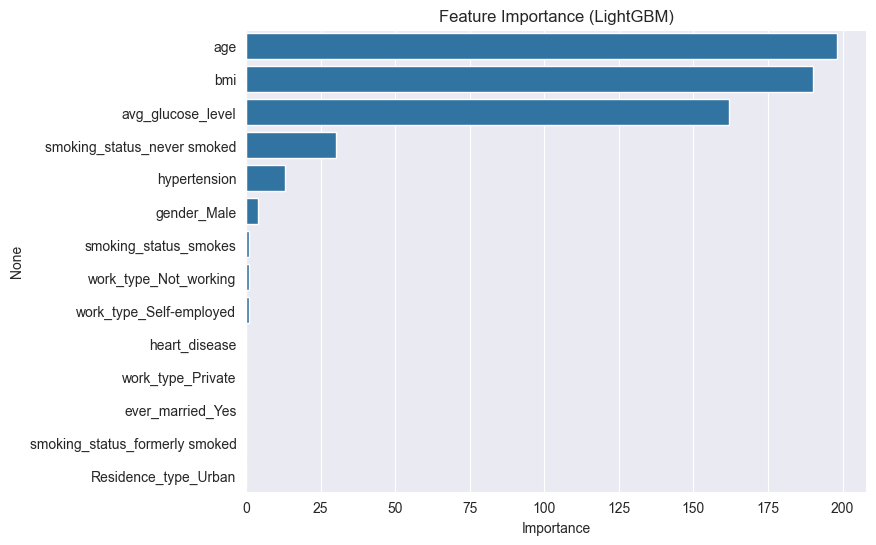

In [191]:
featureImp = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=featureImp.values, y=featureImp.index)
plt.title("Feature Importance (LightGBM)")
plt.xlabel("Importance")
plt.show()

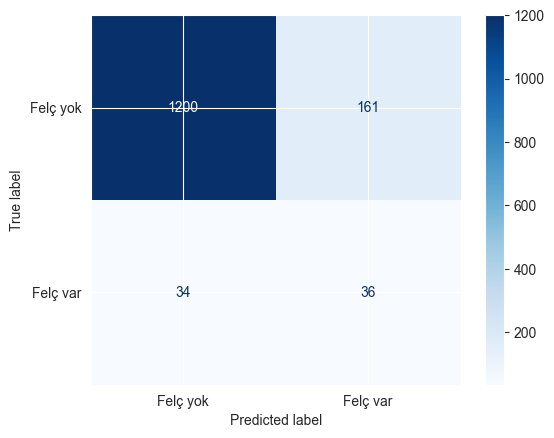

In [192]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(best, X_test, y_test,display_labels=["Felç yok", "Felç var"], cmap="Blues")
plt.show()